In [84]:
#importing the libraries we need to use for data analysis

import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
import matplotlib.pyplot as plt
import seaborn as sns
print("All good")

All good


In [85]:
#load the data set into the data frame(allows us to start exploring for potential data cleanups)
df = pd.read_csv("ai_productivity_dataset_final.csv")

# set display.max_columns to None so we can see all of them
pd.set_option('display.max_columns', None)

# first 5 rows to get a gist of what the data looks like
df.head()

,task_id,client,project_id,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,created_by,updated_at,task_status,workflow_stage,jira_ticket,legacy_ai_flag,content_version
0,T00000,Client_F,P038,mid,Content,report,junior,2,3.0,high,0,hourly,2025-11-20,2025-11-25,10.0,0,7.63,5.14,0.75,True,1,1,2.10,69.93,498.11,346.17,151.94,user_096,2025-11-28,review,finalized,JIRA-49014,true,v1
1,T00001,Client_H,P028,low,Paid Media,release,junior,1,2.0,medium,0,fixed,2026-01-24,2026-01-26,7.0,0,9.52,8.22,0.12,False,1,1,4.48,82.79,847.01,343.18,503.83,user_058,2026-01-26,delivered,client_review,JIRA-84793,false,v1
2,T00002,Client_D,P009,low,Design,dev,junior,3,4.0,medium,0,fixed,2025-09-16,2025-09-23,5.0,1,8.45,6.15,0.37,True,2,0,2.71,76.40,1374.07,365.02,1009.05,user_074,2025-09-17,in_progress,qa,JIRA-42485,true,v2
3,T00003,Client_E,P023,mid,Content,design,mid,3,2.0,low,0,hourly,2025-11-06,2025-11-09,3.0,0,28.35,24.22,0.07,False,4,1,0.00,NaN,2379.11,1514.73,864.38,user_011,2025-11-12,in_progress,briefing,JIRA-53111,false,v1
4,T00004,Client_C,P014,low,Design,article,senior,2,5.0,low,0,fixed,2026-05-02,2026-05-06,7.0,0,5.93,4.44,0.20,True,2,2,0.84,NaN,709.95,335.27,374.68,user_007,2026-05-09,review,execution,JIRA-86006,true,v2


In [86]:
# checking the column names to see what variables we are working with
print("Columns:", df.columns)

# getting general information about the dataset to check for missing values
df.info()

#rows and columns
print("Shape:", df.shape)

Columns: Index(['task_id', 'client', 'project_id', 'client_tier', 'team', 'task_type',
       'seniority', 'task_complexity_score', 'brief_quality_score',
       'deadline_pressure', 'scope_change_flag', 'pricing_model', 'created_at',
       'delivered_at', 'sla_days', 'sla_breach', 'hours_spent',
       'billable_hours', 'ai_usage_pct', 'ai_assisted', 'revisions', 'errors',
       'rework_hours', 'outcome_score', 'revenue', 'cost', 'profit',
       'created_by', 'updated_at', 'task_status', 'workflow_stage',
       'jira_ticket', 'legacy_ai_flag', 'content_version'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3248 entries, 0 to 3247
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   task_id                3248 non-null   str    
 1   client                 3248 non-null   str    
 2   project_id             3248 non-null   str    
 3   client_tier            3248 non-null   str   

In [87]:
#so we don't accidentally change the original dataset
df_clean = df.copy()

In [88]:
#remove columns with no useful information
cols_to_drop = ['task_id', 'client', 'project_id', 'created_by', 'updated_at', 'jira_ticket', 'legacy_ai_flag']
df_clean = df_clean.drop(columns=cols_to_drop)

In [89]:
# check for improperly labeled values
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(), 
      sep='\n\n')

team
Content       803
Media         781
Design        761
SEO           747
seo            29
media          25
content        22
design         19
SEO            18
DESIGN         12
Paid Media      8
Contennt        8
MEDIA           7
Desgn           6
CONTENT         2
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design            456
ad                453
ticket            451
report            447
article           446
dev               435
release           421
article_task       15
ad_task            11
relese             11
ticket_task        11
design_task        10
Ticket              8
Report              8
release_task        8
report_task         7
Design              7
Ad                  6
development         5
creative            5
dev_task            4
repport             4
paid_ad             4
artcle              3
support_ticket      3
Release             3
blog_article        3
DEV             

In [90]:
# set all string values to lowercase and rename those labeled incorrectly
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[col] = df_clean[col].str.lower()

df_clean['team'] = df_clean['team'].replace({
    'seo ': 'seo',
    'contennt': 'content',
    'desgn': 'design',
    'paid media': 'media'
})

df_clean['task_type'] = df_clean['task_type'].replace({
    'article_task': 'task',
    'ad_task': 'ad',
    'relese': 'release',
    'ticket_task': 'ticket',
    'design_task': 'design',
    'release_task': 'release',
    'report_task': 'report',
    'development': 'dev',
    'creative': 'design',
    'dev_task': 'dev',
    'repport': 'report',
    'paid_ad': 'ad',
    'artcle': 'article',
    'support_ticket': 'ticket',
    'blog_article': 'article'
})

In [91]:
# check value counts again to make sure all values were handled properly
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(),
      sep='\n\n')

team
content    835
media      821
design     798
seo        794
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design     478
ad         474
ticket     473
report     466
article    453
dev        446
release    443
task        15
Name: count, dtype: int64

seniority
mid       1296
junior    1190
senior     762
Name: count, dtype: int64

deadline_pressure
medium    1482
low        914
high       852
Name: count, dtype: int64

pricing_model
hourly         1561
fixed          1227
value_based     460
Name: count, dtype: int64

task_status
in_progress    1129
review          866
delivered       769
draft           183
archived        151
blocked         150
Name: count, dtype: int64

workflow_stage
qa               687
client_review    664
finalized        643
briefing         640
execution        614
Name: count, dtype: int64


In [92]:
# drop 15 tasks labeled as "task"
df_clean = df_clean[df_clean['task_type'] != 'task']

In [93]:
#summary of all columns(numerical & categorical);to understand general patterns in the dataa
df_clean.describe(include='all')

,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,task_status,workflow_stage,content_version
count,3233,3233,3233,3233,3233.000000,3164.000000,3233,3233.000000,3233,3233,3196,3197.000000,3233.000000,3233.000000,3151.000000,3089.000000,3233,3233.000000,3233.000000,3162.000000,3100.000000,3233.000000,3233.000000,3233.000000,3233,3233,3233
unique,3,4,7,3,NaN,NaN,3,NaN,3,330,335,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,5,5
top,mid,content,design,mid,NaN,NaN,medium,NaN,hourly,2026-03-27,2026-01-18,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,in_progress,qa,v1
freq,1506,830,478,1294,NaN,NaN,1475,NaN,1555,22,19,NaN,NaN,NaN,NaN,NaN,2548,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1125,682,920
mean,NaN,NaN,NaN,NaN,2.869780,3.181732,NaN,0.137952,NaN,NaN,NaN,5.018142,0.397773,13.055105,8.439149,0.361379,NaN,3.005258,1.014847,2.433680,68.838981,1121.564536,772.210829,349.353707,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,1.196139,1.210987,NaN,0.344903,NaN,NaN,NaN,2.521184,0.489514,11.544270,4.789097,0.199398,NaN,1.803712,1.042311,2.911877,12.624994,843.028776,585.359090,889.807709,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,2.000000,0.000000,0.020000,-1.900000,0.000000,NaN,0.000000,0.000000,0.000000,9.000000,45.000000,77.850000,-8510.549511,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,2.000000,NaN,0.000000,NaN,NaN,NaN,3.000000,0.000000,7.930000,5.085000,0.200000,NaN,2.000000,0.000000,1.110000,60.867500,647.030000,440.460000,-2.860000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.000000,3.000000,NaN,0.000000,NaN,NaN,NaN,5.000000,0.000000,11.120000,7.540000,0.340000,NaN,3.000000,1.000000,1.810000,69.350000,967.570000,649.210000,254.820000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,4.000000,NaN,0.000000,NaN,NaN,NaN,7.000000,1.000000,15.360000,10.695000,0.500000,NaN,4.000000,2.000000,2.940000,77.542500,1364.600000,943.850000,590.580000,NaN,NaN,NaN


# Missing values

Because brief_quality_score, sla_days, billable_hours, ai_usage_pct, rework_hours, and outcome_score are all numeric features we can easily impute them using iterative imputation. We can assume missing values depend on multiple features, therefore this approach is justifiable. Unfortunately, delivered_at can't be imputed, thus these rows will be removed.

client_tier                0
team                       0
task_type                  0
seniority                  0
task_complexity_score      0
brief_quality_score       69
deadline_pressure          0
scope_change_flag          0
pricing_model              0
created_at                 0
delivered_at              37
sla_days                  36
sla_breach                 0
hours_spent                0
billable_hours            82
ai_usage_pct             144
ai_assisted                0
revisions                  0
errors                     0
rework_hours              71
outcome_score            133
revenue                    0
cost                       0
profit                     0
task_status                0
workflow_stage             0
content_version            0
dtype: int64


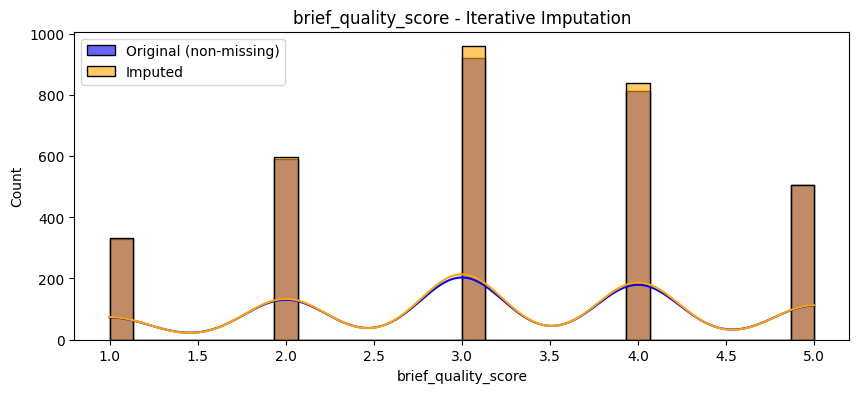

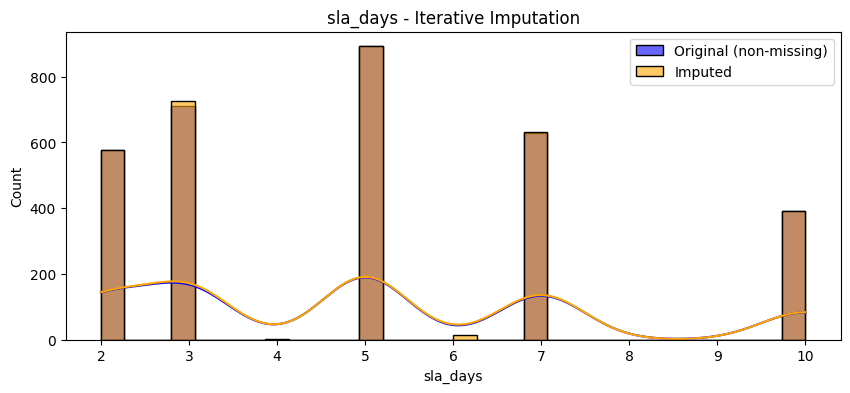

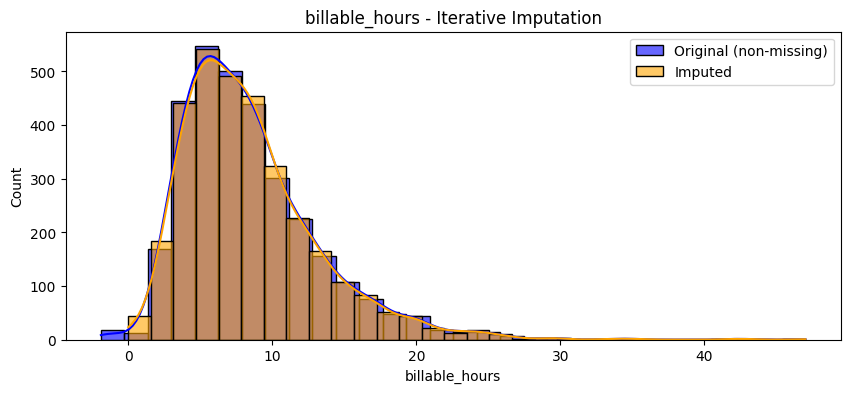

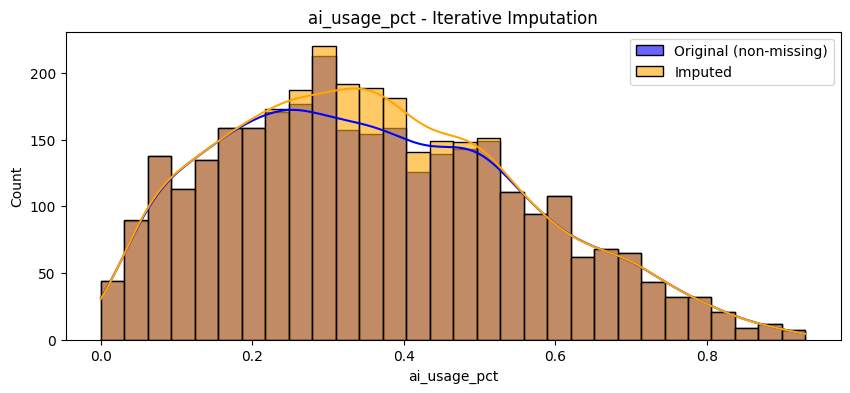

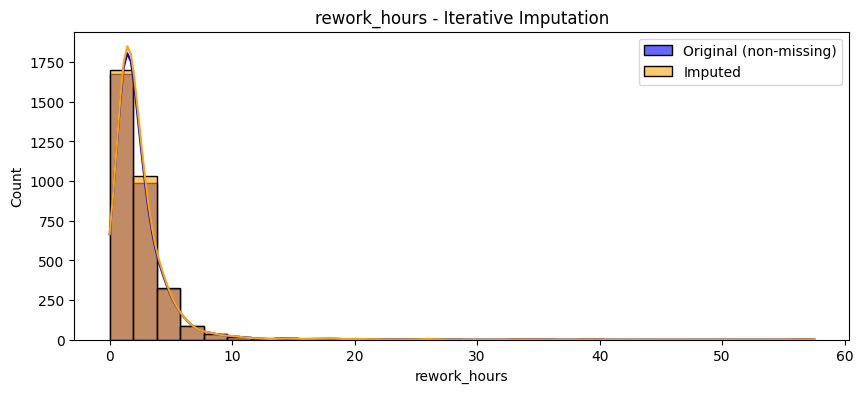

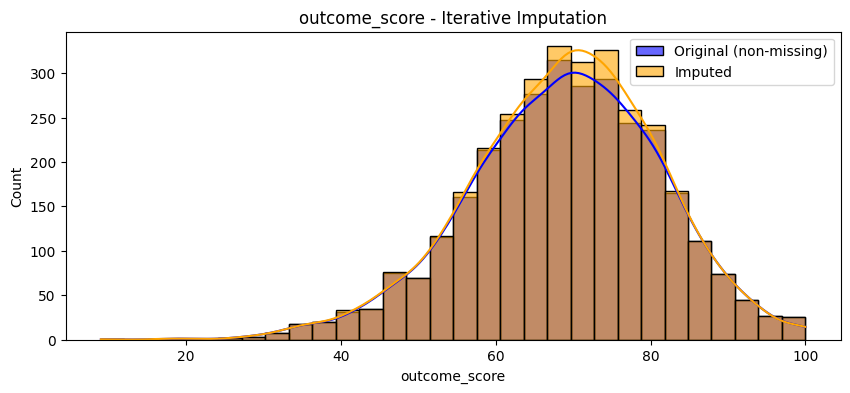

In [94]:
print(df_clean.isnull().sum())

# iterative imputation
df_numerical = df_clean.select_dtypes(include=['number'])

iter_imp = IterativeImputer(random_state=42)
df_iter = pd.DataFrame(iter_imp.fit_transform(df_numerical), columns=df_numerical.columns)

# round brief_quality_score and sla_days such that they are integers
df_iter['brief_quality_score'] = df_iter['brief_quality_score'].round()
df_iter['sla_days'] = df_iter['sla_days'].round()

# remove negative billable_hours
df_iter['billable_hours'] = df_iter['billable_hours'].clip(lower=0)

# plot the orignal vs. imputed distributions of numerical features
def plot_imputation_comparison(original, imputed, title):
    plt.figure(figsize=(10, 4))
    sns.histplot(original.dropna(), kde=True, color='blue', label='Original (non-missing)', bins=30, alpha=0.6)
    sns.histplot(imputed, kde=True, color='orange', label='Imputed', bins=30, alpha=0.6)
    plt.title(title)
    plt.legend()
    plt.show()

for col in df_numerical.columns:
    if df_numerical[col].isnull().any():
        plot_imputation_comparison(df_numerical[col], df_iter[col], f"{col} - Iterative Imputation")

# merge the imputed data back into the original df
df_clean[df_numerical.columns] = df_iter

# drop rows with missing delivered_at values
df_clean = df_clean.dropna()

In [95]:
#checking final shape after cleaning
print("Final shape:", df_clean.shape)
#make sure there arnet missing values left
print(df_clean.isnull().sum())
#confirm no remaining duplicate rows
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Final shape: (3181, 27)
client_tier              0
team                     0
task_type                0
seniority                0
task_complexity_score    0
brief_quality_score      0
deadline_pressure        0
scope_change_flag        0
pricing_model            0
created_at               0
delivered_at             0
sla_days                 0
sla_breach               0
hours_spent              0
billable_hours           0
ai_usage_pct             0
ai_assisted              0
revisions                0
errors                   0
rework_hours             0
outcome_score            0
revenue                  0
cost                     0
profit                   0
task_status              0
workflow_stage           0
content_version          0
dtype: int64
Duplicate rows after cleaning: 0
